In [ ]:
# ==========================================
# 01. CONFIGURACIÓN DEL PROYECTO
# ==========================================

from google.colab import drive
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# Montar Google Drive
drive.mount("/content/drive")

# Semilla reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Directorio del proyecto
BASE_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado"
)

RAW_DIR = BASE_DIR / "datasets" / "raw"
PROCESSED_DIR = BASE_DIR / "datasets" / "processed"
SPLITS_DIR = BASE_DIR / "datasets" / "splits"
REPORT_DIR = BASE_DIR / "resultados"

# Crear directorios necesarios
for directorio in [
    RAW_DIR,
    PROCESSED_DIR,
    SPLITS_DIR,
    REPORT_DIR
]:
    directorio.mkdir(parents=True, exist_ok=True)

print("Proyecto:", BASE_DIR)
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado
PyTorch: 2.11.0+cu130
GPU disponible: True
GPU: Tesla T4


In [ ]:
# ==========================================
# 04. INSPECCIÓN INICIAL DE OPENSUBTITLES
# ==========================================

from pathlib import Path
import pandas as pd
import csv

RAW_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/"
    "traductor_optimizado/datasets/raw"
)

archivos = {
    "train": RAW_DIR / "train.tsv",
    "val": RAW_DIR / "val.tsv",
    "test": RAW_DIR / "test.tsv"
}

datasets = {}

for nombre, ruta in archivos.items():

    df = pd.read_csv(
        ruta,
        sep="\t",
        header=None,
        names=["en", "es", "id_original"],
        dtype=str,
        keep_default_na=False,
        quoting=csv.QUOTE_NONE,
        on_bad_lines="error"
    )

    datasets[nombre] = df

    print(f"\n{'=' * 50}")
    print(f"DATASET: {nombre.upper()}")
    print(f"{'=' * 50}")

    print("Filas:", f"{len(df):,}")
    print("Columnas:", df.columns.tolist())
    print("Nulos:", df.isna().sum().to_dict())

    display(df.head(3))

print("\nRESUMEN GENERAL")

display(
    pd.DataFrame([
        {
            "conjunto": nombre,
            "pares": len(df),
            "columnas": len(df.columns)
        }
        for nombre, df in datasets.items()
    ])
)


DATASET: TRAIN
Filas: 792,070
Columnas: ['en', 'es', 'id_original']
Nulos: {'en': 0, 'es': 0, 'id_original': 0}


,en,es,id_original
0,She might be the future Mrs. Max Russo.,Tengo que conocerla.,0
1,"This isn't getting us anywhere. - No, of cours...",Esto no conduce a ninguna parte.,1
2,It's the moment you've trained for.,Es el momento para el que has entrenado.,2



DATASET: VAL
Filas: 44,004
Columnas: ['en', 'es', 'id_original']
Nulos: {'en': 0, 'es': 0, 'id_original': 0}


,en,es,id_original
0,"Lets go see how a 75,000,000 worth necklace lo...",Vamos a ver cómo luce un collar que vale 75 mi...,13
1,"Uh, no.","Uh, no.",27
2,"went*** - Thank you, dorota.","Gracias, Dorota.",40



DATASET: TEST
Filas: 44,004
Columnas: ['en', 'es', 'id_original']
Nulos: {'en': 0, 'es': 0, 'id_original': 0}


,en,es,id_original
0,How'd you know that?,El 3406.,4
1,And it was like the biggest shock of my life.,Y fue como el shock más grande de mi vida.,17
2,I'll give you some milk.,Te daré leche.,26



RESUMEN GENERAL


,conjunto,pares,columnas
0,train,792070,3
1,val,44004,3
2,test,44004,3


In [ ]:
# ==========================================
# 05. EDA INICIAL DE OPENSUBTITLES
# ==========================================

import pandas as pd
import re
import unicodedata

def normalizar_comparacion(texto):
    texto = unicodedata.normalize("NFC", str(texto))
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip().casefold()

resultados = []

for nombre, df in datasets.items():

    en = df["en"].map(normalizar_comparacion)
    es = df["es"].map(normalizar_comparacion)

    long_en = df["en"].str.split().str.len()
    long_es = df["es"].str.split().str.len()

    resultados.append({
        "conjunto": nombre,
        "pares": len(df),
        "vacios_en": int(en.eq("").sum()),
        "vacios_es": int(es.eq("").sum()),
        "duplicados_pares": int(
            pd.DataFrame({"en": en, "es": es})
            .duplicated().sum()
        ),
        "ingleses_unicos": int(en.nunique()),
        "longitud_media_en": round(long_en.mean(), 2),
        "longitud_media_es": round(long_es.mean(), 2),
        "longitud_max_en": int(long_en.max()),
        "longitud_max_es": int(long_es.max())
    })

eda_resumen = pd.DataFrame(resultados)

display(eda_resumen)

,conjunto,pares,vacios_en,vacios_es,duplicados_pares,ingleses_unicos,longitud_media_en,longitud_media_es,longitud_max_en,longitud_max_es
0,train,792070,0,0,15984,709128,6.57,6.08,30,29
1,val,44004,0,0,905,39485,6.59,6.10,29,29
2,test,44004,0,0,694,39908,6.61,6.12,29,29


In [ ]:
# ==========================================
# 06. VERIFICAR SOLAPAMIENTO ENTRE SPLITS
# ==========================================

# Normalizar temporalmente para comparar
claves = {}

for nombre, df in datasets.items():
    claves[nombre] = {
        "en": set(df["en"].map(normalizar_comparacion)),
        "pares": set(zip(
            df["en"].map(normalizar_comparacion),
            df["es"].map(normalizar_comparacion)
        ))
    }

comparaciones = [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]

resultados_overlap = []

for a, b in comparaciones:
    resultados_overlap.append({
        "comparacion": f"{a} vs {b}",
        "ingles_coincidentes": len(
            claves[a]["en"] & claves[b]["en"]
        ),
        "pares_coincidentes": len(
            claves[a]["pares"] & claves[b]["pares"]
        )
    })

display(pd.DataFrame(resultados_overlap))

,comparacion,ingles_coincidentes,pares_coincidentes
0,train vs val,0,0
1,train vs test,0,0
2,val vs test,0,0


In [ ]:
# ==================================================
# EDA - CONFIGURACIÓN DE GRÁFICOS
# ==================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import csv

BASE_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/"
    "traductor_optimizado"
)

RAW_DIR = BASE_DIR / "datasets" / "raw"
EDA_GRAFICOS_DIR = BASE_DIR / "resultados" / "graficos" / "EDA"
EDA_GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

# Cargar los conjuntos sin modificar sus archivos
datasets = {}

for nombre in ["train", "val", "test"]:
    datasets[nombre] = pd.read_csv(
        RAW_DIR / f"{nombre}.tsv",
        sep="\t",
        header=None,
        names=["en", "es", "id_original"],
        dtype=str,
        keep_default_na=False,
        quoting=csv.QUOTE_NONE,
        on_bad_lines="error"
    )

print("Datasets cargados:")
for nombre, df in datasets.items():
    print(f"{nombre}: {len(df):,} pares")

print("\nDirectorio de gráficos:", EDA_GRAFICOS_DIR)

Datasets cargados:
train: 792,070 pares
val: 44,004 pares
test: 44,004 pares

Directorio de gráficos: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/graficos/EDA


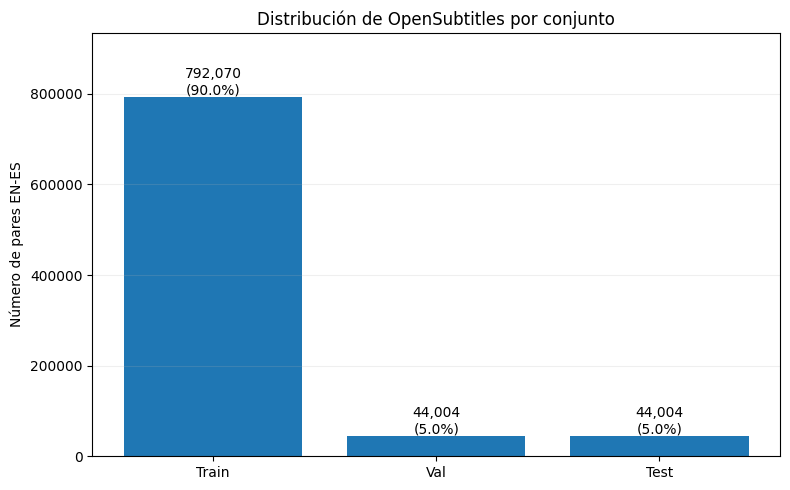

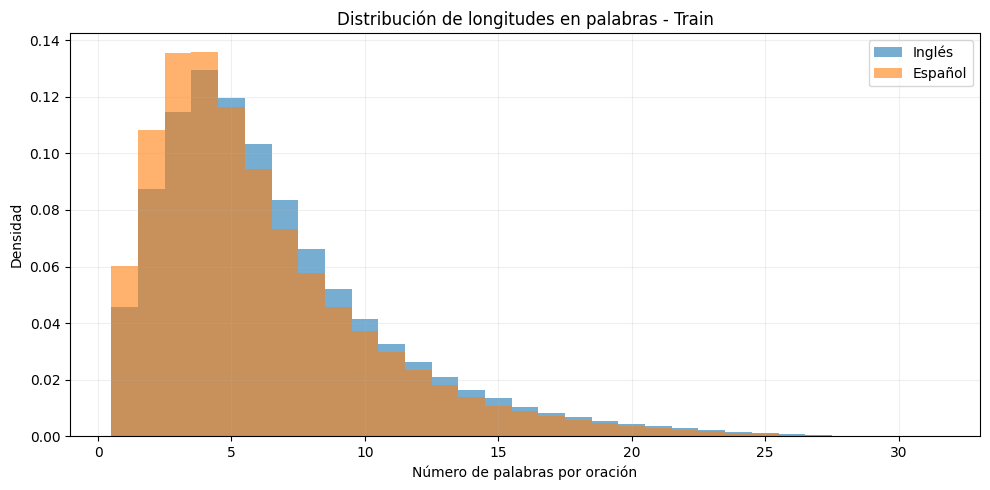

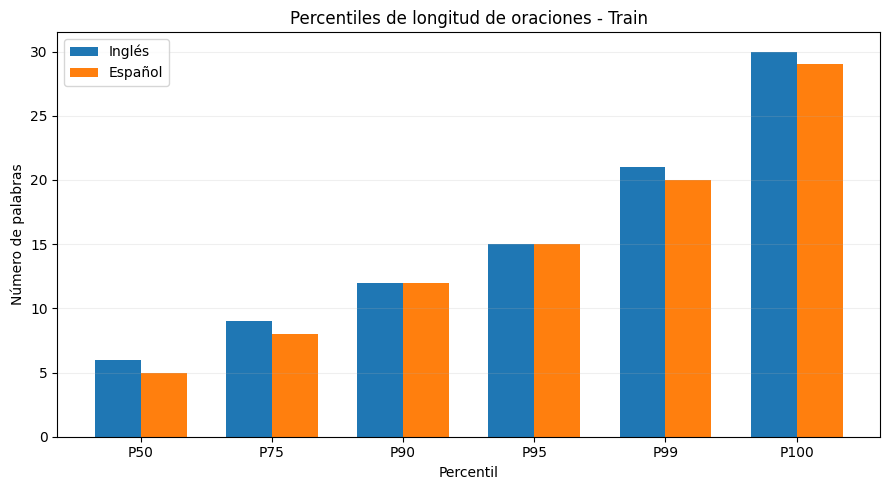

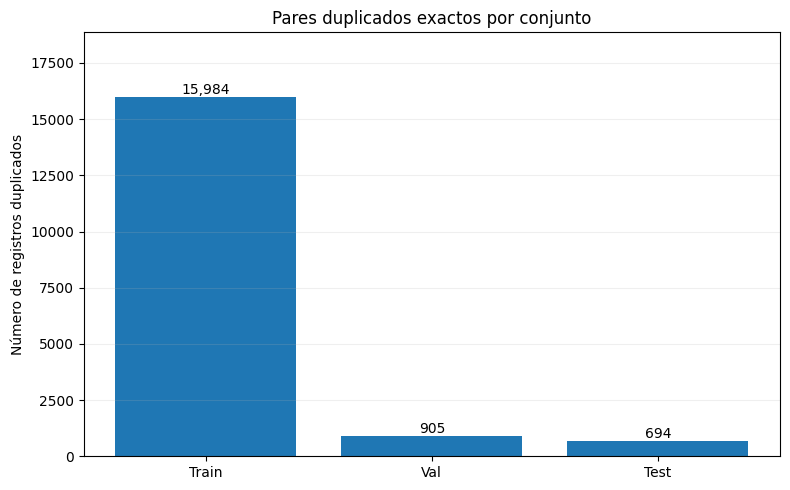

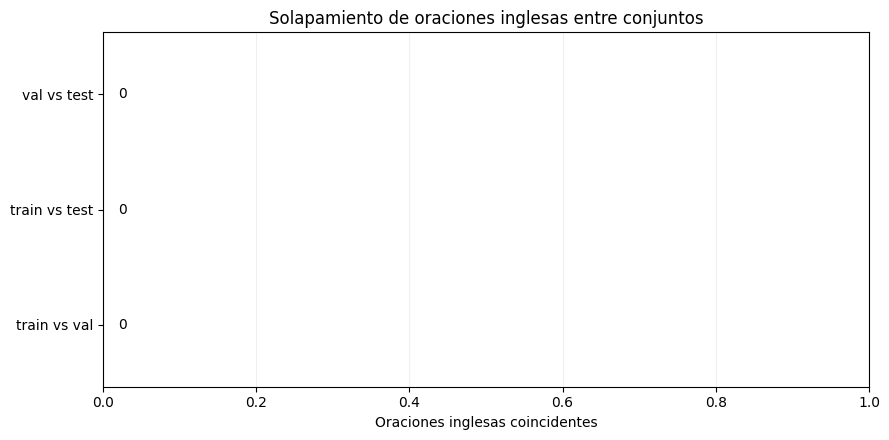


GRÁFICOS DEL EDA GENERADOS:
- 01_distribucion_dataset.png
- 02_distribucion_longitudes_palabras.png
- 03_percentiles_longitudes.png
- 04_duplicados_por_conjunto.png
- 05_solapamiento_conjuntos.png


In [ ]:
# ==================================================
# EDA - VISUALIZACIONES PARA EL INFORME
# ==================================================

import re
import unicodedata

def normalizar_comparacion(texto):
    texto = unicodedata.normalize("NFC", str(texto))
    return re.sub(r"\s+", " ", texto).strip().casefold()

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(
        EDA_GRAFICOS_DIR / nombre,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

nombres = ["Train", "Val", "Test"]
cantidades = [len(datasets[n.lower()]) for n in nombres]

# --------------------------------------------------
# FIGURA 1: DISTRIBUCIÓN DEL DATASET
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(nombres, cantidades)

for barra, cantidad in zip(barras, cantidades):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height(),
        f"{cantidad:,}\n({cantidad/sum(cantidades)*100:.1f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Distribución de OpenSubtitles por conjunto")
ax.set_ylabel("Número de pares EN-ES")
ax.set_ylim(0, max(cantidades) * 1.18)
ax.grid(axis="y", alpha=0.2)

guardar(fig, "01_distribucion_dataset.png")


# --------------------------------------------------
# FIGURA 2: DISTRIBUCIÓN DE LONGITUDES EN PALABRAS
# --------------------------------------------------

train = datasets["train"]

long_en = train["en"].str.split().str.len().to_numpy()
long_es = train["es"].str.split().str.len().to_numpy()

fig, ax = plt.subplots(figsize=(10, 5))

bins = np.arange(0.5, 32.5, 1)

ax.hist(
    long_en, bins=bins, alpha=0.6,
    label="Inglés", density=True
)
ax.hist(
    long_es, bins=bins, alpha=0.6,
    label="Español", density=True
)

ax.set_title("Distribución de longitudes en palabras - Train")
ax.set_xlabel("Número de palabras por oración")
ax.set_ylabel("Densidad")
ax.legend()
ax.grid(alpha=0.2)

guardar(fig, "02_distribucion_longitudes_palabras.png")


# --------------------------------------------------
# FIGURA 3: PERCENTILES DE LONGITUD EN PALABRAS
# --------------------------------------------------

percentiles = [50, 75, 90, 95, 99, 100]

val_en = np.percentile(long_en, percentiles)
val_es = np.percentile(long_es, percentiles)

x = np.arange(len(percentiles))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - ancho/2, val_en, ancho, label="Inglés")
ax.bar(x + ancho/2, val_es, ancho, label="Español")

ax.set_xticks(x)
ax.set_xticklabels([f"P{p}" for p in percentiles])
ax.set_title("Percentiles de longitud de oraciones - Train")
ax.set_xlabel("Percentil")
ax.set_ylabel("Número de palabras")
ax.legend()
ax.grid(axis="y", alpha=0.2)

guardar(fig, "03_percentiles_longitudes.png")


# --------------------------------------------------
# FIGURA 4: DUPLICADOS EXACTOS POR CONJUNTO
# --------------------------------------------------

duplicados = []

for nombre in ["train", "val", "test"]:
    df = datasets[nombre]

    claves = pd.DataFrame({
        "en": df["en"].map(normalizar_comparacion),
        "es": df["es"].map(normalizar_comparacion)
    })

    duplicados.append(int(claves.duplicated().sum()))

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(nombres, duplicados)

for barra, valor in zip(barras, duplicados):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height(),
        f"{valor:,}",
        ha="center",
        va="bottom"
    )

ax.set_title("Pares duplicados exactos por conjunto")
ax.set_ylabel("Número de registros duplicados")
ax.set_ylim(0, max(duplicados) * 1.18)
ax.grid(axis="y", alpha=0.2)

guardar(fig, "04_duplicados_por_conjunto.png")


# --------------------------------------------------
# FIGURA 5: SOLAPAMIENTO ENTRE CONJUNTOS
# --------------------------------------------------

claves_en = {}

for nombre, df in datasets.items():
    claves_en[nombre] = set(
        df["en"].map(normalizar_comparacion)
    )

comparaciones = [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]

solapamientos = [
    len(claves_en[a] & claves_en[b])
    for a, b in comparaciones
]

etiquetas = [f"{a} vs {b}" for a, b in comparaciones]

fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.barh(etiquetas, solapamientos)

for barra, valor in zip(barras, solapamientos):
    ax.text(
        valor + 0.02,
        barra.get_y() + barra.get_height()/2,
        str(valor),
        va="center"
    )

ax.set_xlim(0, max(1, max(solapamientos) * 1.2))
ax.set_title("Solapamiento de oraciones inglesas entre conjuntos")
ax.set_xlabel("Oraciones inglesas coincidentes")
ax.grid(axis="x", alpha=0.2)

guardar(fig, "05_solapamiento_conjuntos.png")

print("\nGRÁFICOS DEL EDA GENERADOS:")
for archivo in sorted(EDA_GRAFICOS_DIR.glob("*.png")):
    print("-", archivo.name)